# Forecasting with TimesFM

Example from book `Time Series Forecasting Using Foundation Models`.

In [6]:
import timesfm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import warnings

warnings.filterwarnings("ignore")

In [7]:
plt.rcParams["font.size"] = 14
plt.rcParams["axes.labelsize"] = 14
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams["ytick.labelsize"] = 14
plt.rcParams["legend.fontsize"] = 14
plt.rcParams["lines.linewidth"] = 2
plt.rcParams["axes.prop_cycle"] = plt.cycler(
    color=[
        "#000072",  # blue
        "#80c21d",  # green
        "#924eae",  # purple
        "#ff0000",  # red
        "#ff9100",  # orange
    ]
)

In [8]:
df = pd.read_csv("../data/walmart_sales_small.csv", parse_dates=["Date"])

df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106


In [9]:
tfm = timesfm.TimesFm(
    hparams=timesfm.TimesFmHparams(
        backend="cpu",  # "gpu" if CUDA is available
        per_core_batch_size=32,
        horizon_len=8,
        num_layers=50,
        use_positional_embedding=False,
        context_len=2048,
    ),
    checkpoint=timesfm.TimesFmCheckpoint(
        huggingface_repo_id="google/timesfm-2.0-500m-pytorch"
    ),
)

Fetching 5 files: 100%|██████████| 5/5 [01:14<00:00, 14.90s/it]


In [10]:
df = df.rename(columns={"Store": "unique_id", "Date": "ds"})
df["ds"] = pd.to_datetime(df["ds"])
df.head()

,unique_id,ds,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106


In [11]:
preds_df = tfm.forecast_on_df(
    inputs=df, freq="W", value_name="Weekly_Sales", num_jobs=-1
)

preds_df.head()

Processing dataframe with multiple processes.
 See https://github.com/google-research/timesfm/blob/master/README.md for updated APIs.
 See https://github.com/google-research/timesfm/blob/master/README.md for updated APIs.
 See https://github.com/google-research/timesfm/blob/master/README.md for updated APIs.
 See https://github.com/google-research/timesfm/blob/master/README.md for updated APIs.
Loaded PyTorch TimesFM, likely because python version is 3.11.11 (main, Dec  3 2024, 17:20:40) [Clang 16.0.0 (clang-1600.0.26.4)].
Loaded PyTorch TimesFM, likely because python version is 3.11.11 (main, Dec  3 2024, 17:20:40) [Clang 16.0.0 (clang-1600.0.26.4)].
Loaded PyTorch TimesFM, likely because python version is 3.11.11 (main, Dec  3 2024, 17:20:40) [Clang 16.0.0 (clang-1600.0.26.4)].
Loaded PyTorch TimesFM, likely because python version is 3.11.11 (main, Dec  3 2024, 17:20:40) [Clang 16.0.0 (clang-1600.0.26.4)].
Finished preprocessing dataframe.
Finished forecasting.


,unique_id,ds,timesfm,timesfm-q-0.1,timesfm-q-0.2,timesfm-q-0.3,timesfm-q-0.4,timesfm-q-0.5,timesfm-q-0.6,timesfm-q-0.7,timesfm-q-0.8,timesfm-q-0.9
0,1,2012-10-28,1568672.000,1448417.75,1488222.500,1521048.250,1542119.875,1568672.000,1592453.000,1619977.375,1657727.250,1707237.125
1,1,2012-11-04,1627054.000,1508357.00,1549427.125,1576797.125,1601039.125,1627054.000,1650516.875,1679306.000,1714782.750,1765155.375
2,1,2012-11-11,1653684.250,1524701.00,1568836.000,1598771.625,1627074.875,1653684.250,1679590.875,1710439.375,1753518.625,1812493.750
3,1,2012-11-18,1671083.625,1527738.00,1576692.875,1612349.625,1643436.500,1671083.625,1704931.125,1740059.875,1783028.500,1855970.500
4,1,2012-11-25,1671467.750,1498093.25,1555082.875,1598249.625,1638091.125,1671467.750,1710975.375,1752939.750,1802804.125,1884323.750


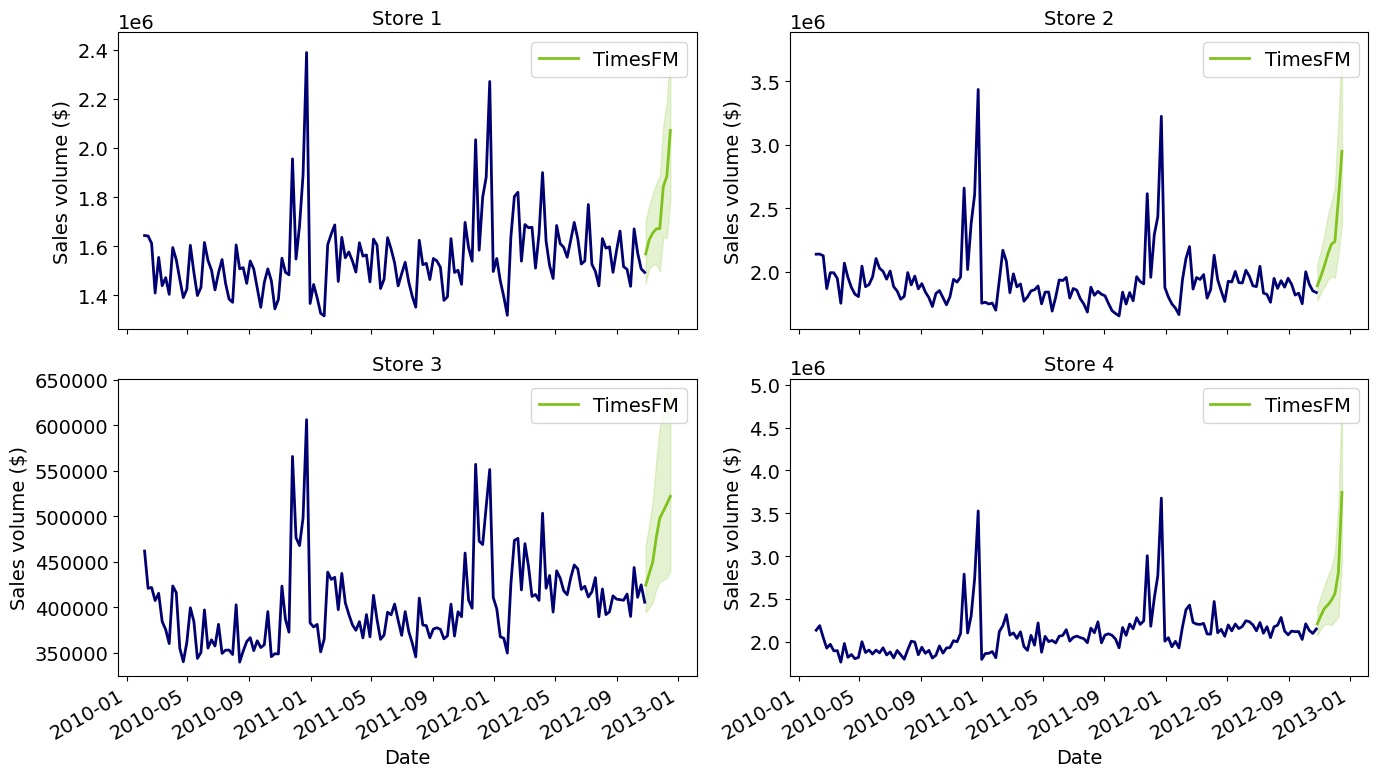

In [12]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 8))

for i, ax in enumerate(axes.flatten()):
    store_id = i + 1
    data = df.query("unique_id == @store_id")
    preds = preds_df.query("unique_id == @store_id")

    ax.plot(data["ds"], data["Weekly_Sales"])
    ax.plot(preds["ds"], preds["timesfm"], label="TimesFM")
    ax.fill_between(
        preds["ds"],
        preds["timesfm-q-0.1"],
        preds["timesfm-q-0.9"],
        color="#80c21d",
        alpha=0.2,
    )

    ax.set_title(f"Store {store_id}")
    ax.set_xlabel("Date")
    ax.set_ylabel("Sales volume ($)")
    ax.legend(loc=1)

fig.autofmt_xdate()
plt.tight_layout()

## Cross-validation with TimesFM

In [13]:
def cross_validation_timesfm(df, h, n_windows, target_col, freq):
    all_preds = []

    for i in range(n_windows, 0, -1):
        input_df = df.iloc[: -(h * i)]

        preds_df = tfm.forecast_on_df(
            inputs=input_df, freq=freq, value_name=target_col, num_jobs=-1
        )

        all_preds.append(preds_df)

    preds = pd.concat(all_preds, axis=0, ignore_index=True)

    return preds

In [14]:
cv_df = df.query("unique_id == 1")

In [15]:
cv_preds = cross_validation_timesfm(
    df=cv_df, h=8, n_windows=4, target_col="Weekly_Sales", freq="W"
)

cv_preds.head()

Processing dataframe with multiple processes.
 See https://github.com/google-research/timesfm/blob/master/README.md for updated APIs.
Loaded PyTorch TimesFM, likely because python version is 3.11.11 (main, Dec  3 2024, 17:20:40) [Clang 16.0.0 (clang-1600.0.26.4)].
Finished preprocessing dataframe.
Finished forecasting.
Processing dataframe with multiple processes.
 See https://github.com/google-research/timesfm/blob/master/README.md for updated APIs.
Loaded PyTorch TimesFM, likely because python version is 3.11.11 (main, Dec  3 2024, 17:20:40) [Clang 16.0.0 (clang-1600.0.26.4)].
Finished preprocessing dataframe.
Finished forecasting.
Processing dataframe with multiple processes.
 See https://github.com/google-research/timesfm/blob/master/README.md for updated APIs.
Loaded PyTorch TimesFM, likely because python version is 3.11.11 (main, Dec  3 2024, 17:20:40) [Clang 16.0.0 (clang-1600.0.26.4)].
Finished preprocessing dataframe.
Finished forecasting.
Processing dataframe with multiple pr

,unique_id,ds,timesfm,timesfm-q-0.1,timesfm-q-0.2,timesfm-q-0.3,timesfm-q-0.4,timesfm-q-0.5,timesfm-q-0.6,timesfm-q-0.7,timesfm-q-0.8,timesfm-q-0.9
0,1,2012-03-18,1621625.375,1465747.125,1516343.125,1555531.000,1587567.250,1621625.375,1656559.500,1698278.250,1753464.125,1844324.875
1,1,2012-03-25,1634064.875,1469694.750,1521617.250,1561141.125,1596940.375,1634064.875,1673763.500,1719128.000,1780867.750,1883812.625
2,1,2012-04-01,1641014.125,1468004.875,1521347.500,1561576.500,1600616.750,1641014.125,1685151.500,1737651.375,1806150.000,1920253.250
3,1,2012-04-08,1635624.000,1458029.125,1511759.750,1554380.750,1594870.750,1635624.000,1682416.375,1736385.125,1808363.500,1928730.875
4,1,2012-04-15,1626994.750,1450906.750,1502575.750,1544984.625,1584879.000,1626994.750,1673781.750,1730081.000,1803576.375,1928450.750


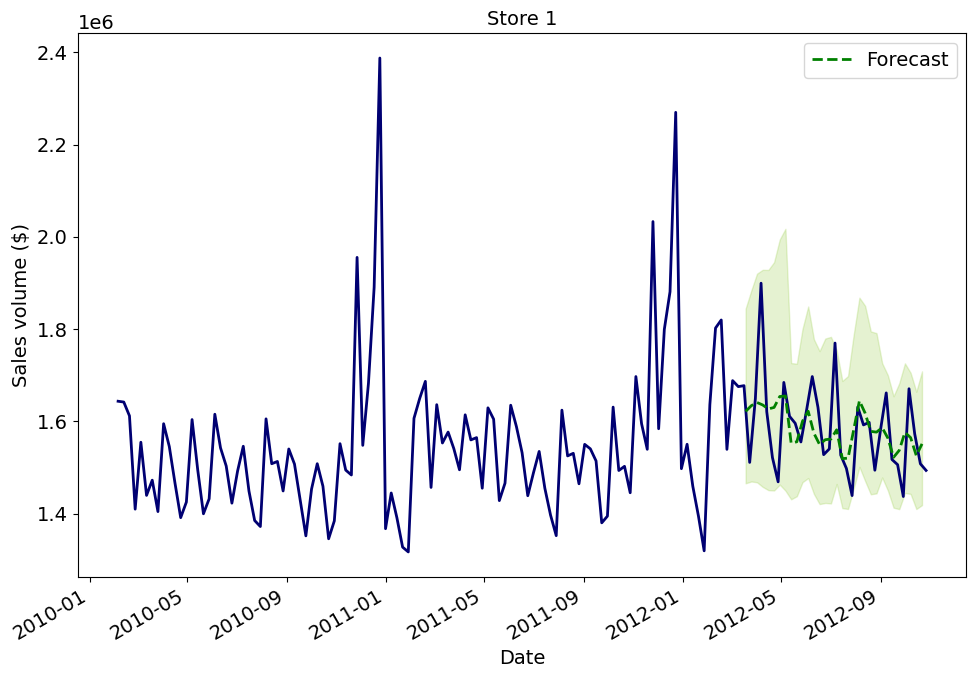

In [16]:
fig, ax = plt.subplots(figsize=(10, 7))

ax.plot(cv_df["ds"], cv_df["Weekly_Sales"])
ax.plot(cv_preds["ds"], cv_preds["timesfm"], ls="--", color="green", label="Forecast")
ax.fill_between(
    cv_preds["ds"],
    cv_preds["timesfm-q-0.1"],
    cv_preds["timesfm-q-0.9"],
    color="#80c21d",
    alpha=0.2,
)

ax.set_title(f"Store 1")
ax.set_xlabel("Date")
ax.set_ylabel("Sales volume ($)")
ax.legend(loc=1)

fig.autofmt_xdate()
plt.tight_layout()

In [17]:
eval_df = cv_preds[["unique_id", "ds", "timesfm"]]
eval_df["Weekly_Sales"] = cv_df["Weekly_Sales"][-32:].values

In [18]:
from utilsforecast.losses import mae, smape
from utilsforecast.evaluation import evaluate

evaluation = evaluate(
    eval_df,
    metrics=[mae, smape],
    models=["timesfm"],
    target_col="Weekly_Sales",
    id_col="unique_id",
)

evaluation

,unique_id,metric,timesfm
0,1,mae,61684.417187
1,1,smape,0.019244


## Forecasting with covariates

In [19]:
train = cv_df[:-32]
test = cv_df[-32:]

train.head()

,unique_id,ds,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106


In [20]:
from collections import defaultdict


# Data pipelining
def get_batched_data_fn(
    batch_size: int = 2,
    context_len: int = 64,
    horizon_len: int = 32,
):
    examples = defaultdict(list)

    num_examples = 0
    for start in range(0, len(cv_df) - (context_len + horizon_len), horizon_len):
        num_examples += 1
        examples["inputs"].append(
            train["Weekly_Sales"][start : (context_end := start + context_len)].tolist()
        )
        examples["Holiday_Flag"].append(
            train["Holiday_Flag"][start : context_end + horizon_len].tolist()
        )
        examples["outputs"].append(
            train["Weekly_Sales"][context_end : (context_end + horizon_len)].tolist()
        )

    def data_fn():
        for i in range(1 + (num_examples - 1) // batch_size):
            yield {
                k: v[(i * batch_size) : ((i + 1) * batch_size)]
                for k, v in examples.items()
            }

    return data_fn

In [21]:
tfm_h32 = timesfm.TimesFm(
    hparams=timesfm.TimesFmHparams(
        backend="cpu",  # "gpu" if CUDA is available
        per_core_batch_size=32,
        horizon_len=32,
        num_layers=50,
        use_positional_embedding=False,
        context_len=2048,
    ),
    checkpoint=timesfm.TimesFmCheckpoint(
        huggingface_repo_id="google/timesfm-2.0-500m-pytorch"
    ),
)

Fetching 5 files: 100%|██████████| 5/5 [00:00<00:00, 83220.32it/s]


In [22]:
input_data = get_batched_data_fn()

for i, example in enumerate(input_data()):
    cov_forecast, _ = tfm_h32.forecast_with_covariates(
        inputs=example["inputs"],
        dynamic_numerical_covariates={},
        dynamic_categorical_covariates={
            "Holiday_Flag": example["Holiday_Flag"],
        },
        static_numerical_covariates={},
        static_categorical_covariates={},
        freq=[1] * len(example["inputs"]),
        xreg_mode="xreg + timesfm",
        ridge=0.0,
        force_on_cpu=False,
        normalize_xreg_target_per_input=True,
    )
    print(f"Done with round {i}")

Done with round 0


In [ ]:
no_cov_preds = tfm_h32.forecast_on_df(
    inputs=train, freq="W", value_name="Weekly_Sales", num_jobs=-1
)

no_cov_preds.head()

Processing dataframe with multiple processes.
 See https://github.com/google-research/timesfm/blob/master/README.md for updated APIs.
Loaded PyTorch TimesFM, likely because python version is 3.11.11 (main, Dec  3 2024, 17:20:40) [Clang 16.0.0 (clang-1600.0.26.4)].
Finished preprocessing dataframe.
Finished forecasting.


,unique_id,ds,timesfm,timesfm-q-0.1,timesfm-q-0.2,timesfm-q-0.3,timesfm-q-0.4,timesfm-q-0.5,timesfm-q-0.6,timesfm-q-0.7,timesfm-q-0.8,timesfm-q-0.9
0,1,2012-03-18,1621625.375,1465747.125,1516343.125,1555531.000,1587567.250,1621625.375,1656559.500,1698278.250,1753464.125,1844324.875
1,1,2012-03-25,1634064.875,1469694.750,1521617.250,1561141.125,1596940.375,1634064.875,1673763.500,1719128.000,1780867.750,1883812.625
2,1,2012-04-01,1641014.125,1468004.875,1521347.500,1561576.500,1600616.750,1641014.125,1685151.500,1737651.375,1806150.000,1920253.250
3,1,2012-04-08,1635624.000,1458029.125,1511759.750,1554380.750,1594870.750,1635624.000,1682416.375,1736385.125,1808363.500,1928730.875
4,1,2012-04-15,1626994.750,1450906.750,1502575.750,1544984.625,1584879.000,1626994.750,1673781.750,1730081.000,1803576.375,1928450.750


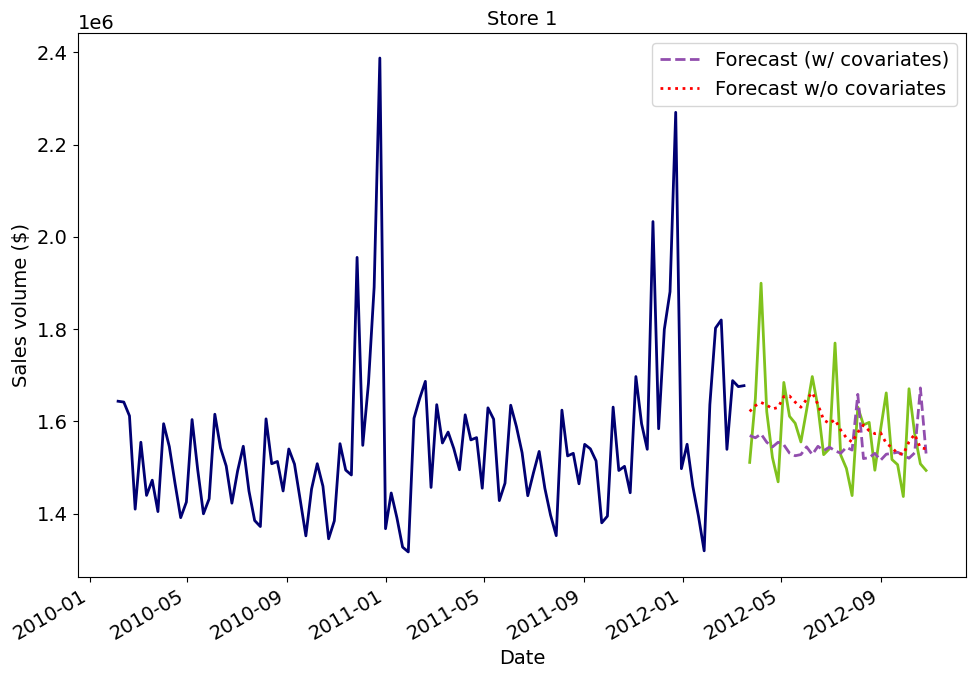

In [ ]:
fig, ax = plt.subplots(figsize=(10, 7))

ax.plot(train["ds"], train["Weekly_Sales"])
ax.plot(test["ds"], test["Weekly_Sales"])
ax.plot(test["ds"], cov_forecast[0], ls="--", label="Forecast (w/ covariates)")
ax.plot(test["ds"], no_cov_preds["timesfm"], ls=":", label="Forecast w/o covariates")

ax.set_title(f"Store 1")
ax.set_xlabel("Date")
ax.set_ylabel("Sales volume ($)")
ax.legend(loc=1)

fig.autofmt_xdate()
plt.tight_layout()

In [25]:
from utilsforecast.losses import mae, smape
from utilsforecast.evaluation import evaluate

eval_df = test[["unique_id", "ds", "Weekly_Sales"]]
eval_df["timesfm_cov"] = cov_forecast[0]
eval_df["timesfm"] = no_cov_preds["timesfm"].values

evaluation = evaluate(
    eval_df,
    metrics=[mae, smape],
    models=["timesfm", "timesfm_cov"],
    target_col="Weekly_Sales",
    id_col="unique_id",
)

evaluation

,unique_id,metric,timesfm,timesfm_cov
0,1,mae,64578.480156,81960.532344
1,1,smape,0.020201,0.025718
